# Group Exam GRA 41624 Deep Learning and Explainable AI

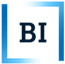

Course code and name: GRA 4162 Deep Learning and Explainable AI

Type of exam: Home exam

Start date: 13/11/2026 09:00

Finish date: 04/12/2026 12:00 

Term: Fall 2026

Weight in the total grade: 40%

To be answered in groups: 1-3 students

Allowed file types for answer paper: Jupyter notebook (.ipynb)

Separate attachment allowed: No

Number of files allowed to be uploaded: 1

### Deliverables and submission instructions

- Fill in all Code cells with Python code. Use comments in the code. Follow the instructions from the previous cell.

- Add Markdown cells if you need to add a Comment.

- Submit the notebook. Before you submit it, run the entire notebook to ensure all code is compiled correctly and results can be reproduced.

### Allowed aids

- You are allowed to use all the course materials.

- You are NOT allowed to use artificial intelligence tools in directly solving your exercises.

- You are NOT allowed to use help from people that are not in your project group.

In [2]:
#=======================================
# import packages
#=======================================
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.keras import TqdmCallback

I0000 00:00:1795689214.342243  610181 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795689214.672965  610181 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795689216.404080  610181 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Exercise 1. GDP prediction with RNNs (35 points)

In this exercise, you will use historical US macroeconomic data from the Federal Reserve Economic Data (FRED) database. The dataset contains four macroeconomic variables: GDP, inflation, the unemployment rate, and money growth, observed over a specified period (period and frequency) and can be found here:

https://fred.stlouisfed.org/series/GDPC1

https://fred.stlouisfed.org/series/CPIAUCSL

https://fred.stlouisfed.org/series/unrate

https://fred.stlouisfed.org/series/M2SL/nMost

You will build several recurrent neural networks to predict GDP using univariate and multivariate inputs. Follow the instructions below and solve the exercise step by step.

#### 1 a) Load, preprocess, and visualize the data (5 points) 

Load the data from the attached file named 'US_macro_FRED.csv' and remove any missing values. Then, plot all variables against time.

Mean of GDPC1: 11823.339468634687
Standard Deviation of GDPC1: 6089.130843151077
                     GDPC1  CPIAUCSL  UNRATE   M2SL
observation_date                                   
1959-01-01        3352.129    28.993     5.8  287.8
1959-04-01        3427.667    29.043     5.1  292.1
1959-07-01        3430.057    29.193     5.3  296.1
1959-10-01        3439.832    29.370     5.6  297.1
1960-01-01        3517.181    29.397     5.1  298.6
                      GDPC1  CPIAUCSL  UNRATE     M2SL
observation_date                                      
2025-07-01        24112.966   323.235     4.3  22071.1
2025-10-01        24125.479   325.547     4.5  22268.4
2026-01-01        24274.383   328.114     4.3  22524.3
2026-04-01        24408.011   332.985     4.3  22928.9
2026-07-01        24611.077   334.414     4.1  23297.4
<class 'pandas.DataFrame'>
DatetimeIndex: 271 entries, 1959-01-01 to 2026-07-01
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    ----

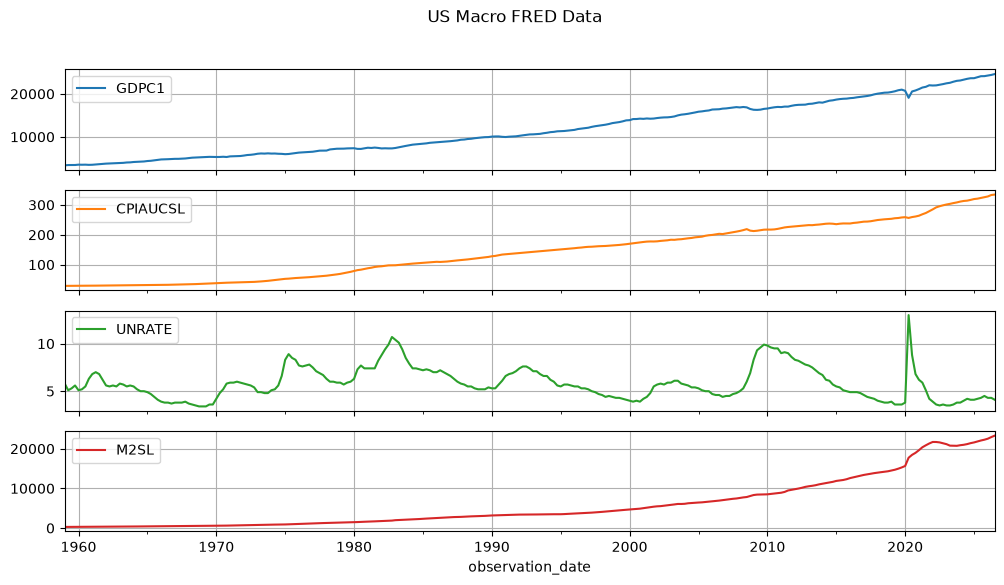

In [2]:
def load_data(data_path):
    """
    Load the times series data from a CSV file, preprocess it visualise it and saves a copy.

    Parameters:
    data_path (str): The path to the CSV file.

    Returns:
    pd.DataFrame: A DataFrame containing the processed data.
    """
    # Load data:
    _df = pd.read_csv(data_path)
    _df['observation_date'] = pd.to_datetime(_df['observation_date'],format="%m/%d/%y")

    # Fix the dates to the correct century
    _df['observation_date'] = _df['observation_date'].apply(lambda x: x.replace(year=x.year - 100) if x.year > 2026 else x)

    # Clean the data by dropping rows with missing values
    _df.dropna(inplace=True)

    # Set the 'observation_date' column as the index of the DataFrame
    _df.set_index('observation_date', inplace=True)

    # Plot the data to visualize it
    _df.plot(subplots=True, figsize=(12, 6), title='US Macro FRED Data',grid=True)

    return _df.copy(deep=True)  # Return a copy of the DataFrame to avoid modifying the original data

source_data = load_data('US_macro_FRED.csv')
source_target_mean = float(source_data["GDPC1"].mean())
source_target_std = float(source_data["GDPC1"].std())

print(f"Mean of GDPC1: {source_target_mean}")
print(f"Standard Deviation of GDPC1: {source_target_std}")
print(source_data.head(5))
print(source_data.tail(5))
print(source_data.info())

In [3]:
def make_generators(data, feature_cols, target_col, sequence_length):
    """
    Create univariate and multivariate time series generators from the source data.

    parameters:
    data (pd.DataFrame): The source data containing the features and target.
    feature_cols (list): List of column names for the features.
    target_col (str): Name of the target column.
    sequence_length (int): Length of the input sequence.

    Returns:
    tuple: A tuple containing the univariate and multivariate time series generators.
    """

    # Input windows of shape (batch, sequence_length, num_features)
    _input_data_mult = data[feature_cols].to_numpy()

    # Simple input for univariate generator based on the target column
    _input_data_uni = data[[target_col]].to_numpy()

    # Target at the step immediately following each 4-step window
    _target_data = data[target_col].to_numpy()[sequence_length:]

    # Univariate Time Series Generator based on 4 preceding periods
    _uni = tf.keras.preprocessing.timeseries_dataset_from_array(
        data=_input_data_uni,
        targets=_target_data,
        sequence_length=sequence_length,
        batch_size = 16
    )

    # Multivariate Time Series Generator based on 4 preceding periods
    _multi = tf.keras.preprocessing.timeseries_dataset_from_array(
        data=_input_data_mult,
        targets=_target_data,
        sequence_length=sequence_length,
        batch_size = 16
    )

    return _uni, _multi


# Time Series Generator based on 4 preceding periods
uni_generator, multi_generator = make_generators(source_data,                                             
                                                feature_cols=["M2SL", "UNRATE", "GDPC1", "CPIAUCSL"],
                                                target_col="GDPC1",
                                                sequence_length=4)

# Time series normalized target data
uni_norm = tf.keras.layers.Normalization(axis=-1)
uni_norm.adapt(source_data[["GDPC1"]].to_numpy())
multi_norm = tf.keras.layers.Normalization(axis=-1)
multi_norm.adapt(source_data[["M2SL", "UNRATE", "GDPC1", "CPIAUCSL"]].to_numpy())

I0000 00:00:1795629836.168453  523443 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


#### 1 c) Build Recurrent Neural Networks (10 points) 

Build two models — an RNN and an LSTM — to predict GDP based on the previous four periods. Use one hidden layer in each model and train them using the data generated by the univariate time series generator.
After training, print the model summary and explain the number of parameters shown in the RNN summary table.

In [4]:
# MAKE A SIZE APPROPRIATE LEARNING RATE FOR THE OPTIMIZER
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.1,
    decay_steps=500,
    decay_rate=0.8
)

#----

# Define sequential model.
ex1c_RNNmodel = tf.keras.models.Sequential()

# Define Input layer:
ex1c_RNNmodel.add(tf.keras.Input(shape=(4,1))) # 4 timesteps, 1 feature 
ex1c_RNNmodel.add(uni_norm)

# Define recurrent layer with 1 hidden units:
ex1c_RNNmodel.add(tf.keras.layers.SimpleRNN(1, activation="tanh"))

# Define output layer:
ex1c_RNNmodel.add(tf.keras.layers.Dense(
    1,
    activation="linear",
    kernel_initializer=tf.keras.initializers.Constant(source_target_std),
    bias_initializer=tf.keras.initializers.Constant(source_target_mean)
    )
)

# Compile the model:
ex1c_RNNmodel.compile(loss="mse", optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule))

# Fit model to data using generator.
ex1c_RNNmodel.fit(uni_generator, epochs=500, callbacks=[TqdmCallback(verbose=1)],verbose=0)

# Print model summary:
ex1c_RNNmodel.summary()

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

/home/lipes/miniconda3/envs/tf_W_sklearn/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795629837.872040  523536 service.cc:153] XLA service 0x73eedc0426a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795629837.872069  523536 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1795629837.901009  523536 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795629838.024409  523536 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1795629838.446316  523536 devi

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 4, 1)           │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19 (84.00 B)

 Trainable params: 5 (20.00 B)

 Non-trainable params: 3 (16.00 B)

 Optimizer params: 11 (48.00 B)

In [5]:
# Define sequential model.
ex1c_LSTMmodel = tf.keras.models.Sequential()

# Define Input layer:
ex1c_LSTMmodel.add(tf.keras.Input(shape=(4,1))) # 4 timesteps, 1 feature
ex1c_LSTMmodel.add(uni_norm)

# Define recurrent layer with 1 hidden units:
ex1c_LSTMmodel.add(tf.keras.layers.LSTM(1, activation="tanh"))

# Define output layer:
ex1c_LSTMmodel.add(tf.keras.layers.Dense(
    1,
    activation="linear",
    kernel_initializer=tf.keras.initializers.Constant(source_target_std),
    bias_initializer=tf.keras.initializers.Constant(source_target_mean)
    )
)

# Compile the model:
ex1c_LSTMmodel.compile(loss="mse", optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule))

# Fit model to data using generator.
ex1c_LSTMmodel.fit(uni_generator, epochs=500, callbacks=[TqdmCallback(verbose=1)],verbose=0)

# Print model summary:
ex1c_LSTMmodel.summary()

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 4, 1)           │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 1)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46 (192.00 B)

 Trainable params: 14 (56.00 B)

 Non-trainable params: 3 (16.00 B)

 Optimizer params: 29 (120.00 B)

It can be seen that, in the RNN part of the models, the Normal RNN has exactly 4 times less parameters than the long short-term memory (LSTM) model. This is exactly as expected as in LSTM each hidden layer has 4 gates with their own parameters instead of the single parameter per hidden layer so the amount of parameters will linearly be 4 times larger

#### 1 d) Build LSTM with two hidden layers (5 points) 

Define an LSTM model with two hidden layers and train it using the univariate data generator.
Print the model summary.

In [6]:
# Define sequential model.
ex1d_LSTMmodel = tf.keras.models.Sequential()

# Define Input layer:
ex1d_LSTMmodel.add(tf.keras.Input(shape=(4,1))) # 4 timesteps, 1 feature 
ex1d_LSTMmodel.add(uni_norm)

# Define recurrent layer with 2 hidden units:
ex1d_LSTMmodel.add(tf.keras.layers.LSTM(2, activation="tanh"))

# Define output layer:
ex1d_LSTMmodel.add(tf.keras.layers.Dense(
    1,
    activation="linear",
    kernel_initializer=tf.keras.initializers.Constant(source_target_std),
    bias_initializer=tf.keras.initializers.Constant(source_target_mean)
    )
)

# Compile the model:
ex1d_LSTMmodel.compile(loss="mse", optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule))

# Fit model to data using generator.
ex1d_LSTMmodel.fit(uni_generator, epochs=500, callbacks=[TqdmCallback(verbose=1)],verbose=0)

# Print model summary:
ex1d_LSTMmodel.summary()

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 4, 1)           │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 2)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109 (444.00 B)

 Trainable params: 35 (140.00 B)

 Non-trainable params: 3 (16.00 B)

 Optimizer params: 71 (288.00 B)

#### 1 e) Build a multivariate LSTM model (5 points) 

Build a multivariate LSTM model with one hidden layer and train it using the multivariate data generator.
After training, print the model summary. 

In [7]:
# Define sequential model.
ex1e_multiLSTMmodel = tf.keras.models.Sequential()

# Define Input layer:
ex1e_multiLSTMmodel.add(tf.keras.Input(shape=(4,4))) # 4 timesteps, 4 features
ex1e_multiLSTMmodel.add(multi_norm)

# Define recurrent layer with 1 hidden unit:
ex1e_multiLSTMmodel.add(tf.keras.layers.LSTM(1, activation="tanh"))

# Define output layer:
ex1e_multiLSTMmodel.add(tf.keras.layers.Dense(
    1,
    activation="linear",
    kernel_initializer=tf.keras.initializers.Constant(source_target_std),
    bias_initializer=tf.keras.initializers.Constant(source_target_mean)
    )
)

# Compile the model:
ex1e_multiLSTMmodel.compile(loss="mse", optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule))

# Fit model to data using generator.
ex1e_multiLSTMmodel.fit(multi_generator, epochs=500, callbacks=[TqdmCallback(verbose=1)],verbose=0)

# Print model summary:
ex1e_multiLSTMmodel.summary()

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 4, 4)           │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 1)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88 (360.00 B)

 Trainable params: 26 (104.00 B)

 Non-trainable params: 9 (40.00 B)

 Optimizer params: 53 (216.00 B)

#### 1 f) Plot and compare predictions(5 points) 

Plot and compare the predictions from the four networks with the true data.
Comment on and discuss the results.

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
[[5696.37  ]
 [5696.148 ]
 [5696.344 ]
 [5696.7554]
 [5697.894 ]]


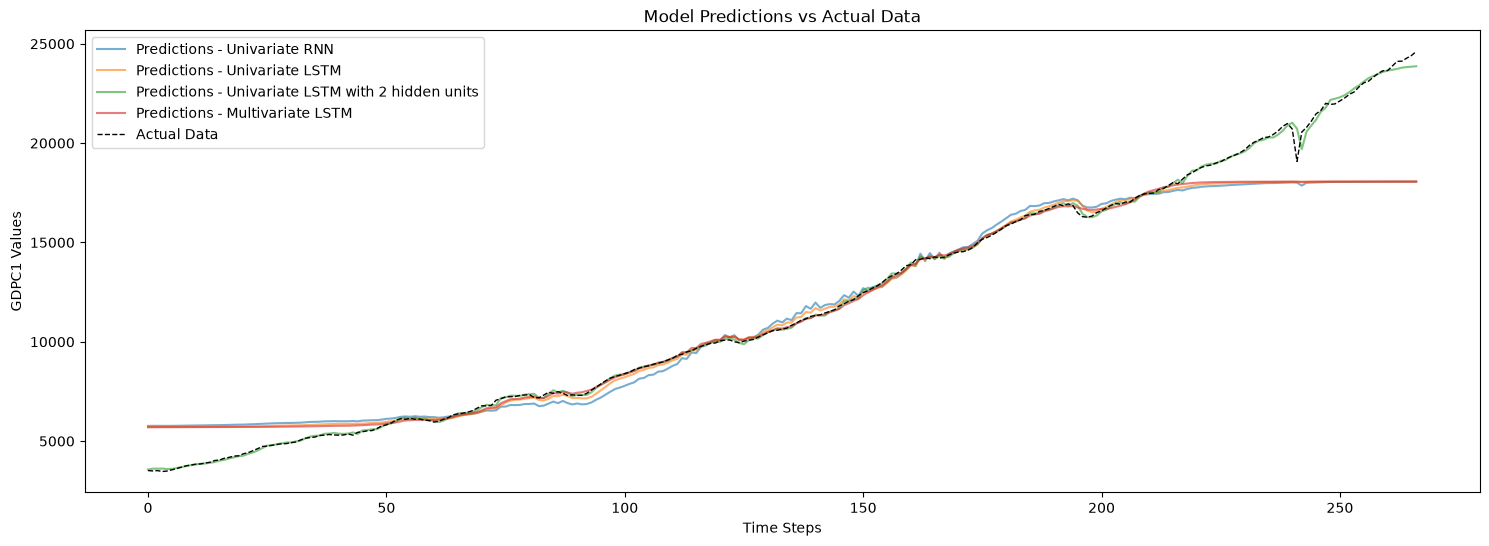

In [ ]:
def plot_predictions(model_titel):
    """
    Plot the predictions of the model against the actual data.

    Parameters:
    model_title (dict): the models to be plotted together and what to call them.
    """
    # Create a new figure for the plot
    plt.figure(figsize=(18, 6))

    # Loop through each model and its title in the provided dictionary
    for model, title in model_titel.items():
        if "multi" in title.lower():
            # Use the multivariate generator for model predictions
            predictions = model.predict(multi_generator)
        else:
            # Use the univariate generator for model predictions
            predictions = model.predict(uni_generator)

        # Plot the predictions with a label
        plt.plot(predictions, alpha=0.6, linewidth=1.5, label=f'Predictions - {title}')

    # Plot the actual target data for comparison
    plt.plot(source_data['GDPC1'].values[4:], label='Actual Data',linestyle="--" , color='black', linewidth=1)

    # Add title and labels to the plot
    plt.title('Model Predictions vs Actual Data')
    plt.xlabel('Time Steps')
    plt.ylabel('GDPC1 Values')

    # Add a legend to differentiate between models and actual data
    plt.legend()

    # Display the plot
    plt.show()

plot_predictions({
    ex1c_RNNmodel: "Univariate RNN",
    ex1c_LSTMmodel: "Univariate LSTM",
    ex1d_LSTMmodel: "Univariate LSTM with 2 hidden units",
    ex1e_multiLSTMmodel: "Multivariate LSTM"
})

It is possible to see that all models can somewhat follow the original line to some extent. The most notable difference to spot is that 3 of the 4 models are made with only a single layer and thus are at most capable of acting like an S curve. This explains why these single models fail at the start and end of the time series. In contrast, the model in green that was made with 2 hidden layers can handle these edges and thus follow the original line even better.
It is also possible to notice that the simple RNN is less capable of reacting to changes and thus its predictions are consistently deviated from the truth. The multivariate model also seems to have successfully incorporated the additional information to be the model that best followed the curves in the truth despite not being flexible enough to change fast enough like mentioned before.

### Exercise 2. Image classification with CNNs (35 points)

In this exercise, you will build and train a CNN using the Street View House Numbers (SVHN) **cropped** dataset:

https://ufldl.stanford.edu/housenumbers

After training the CNN, you will use LIME to explain the model's prediction for one selected image from the test set. 

Follow the instructions below and solve the exercise step by step.

#### 2 a) Download and preprocess data (5 points) 

The SVHN dataset consists of real-world images of individual digits extracted from Google Street View images. Each image is 32 × 32 pixels with three colour channels (RGB), and the objective is to classify each image into one of ten digit classes (0–9). 

Download the set from the link provided above (Note: There is an extra dataset on the provided link (extra_32x32.mat) which is quite large. You do not need to download that one but only 'train_32x32.mat' and 'test_32x32.mat' files!)

Explore the dataset by printing the shapes of the training and test data and their labels.
Display the first five images along with their corresponding class names. Finally, normalize the pixel values to the range [0, 1].



x_train shape: (73257, 32, 32, 3)
y_train shape: (73257,)
x_test shape: (26032, 32, 32, 3)
y_test shape: (26032,)
Sample images from the training set:


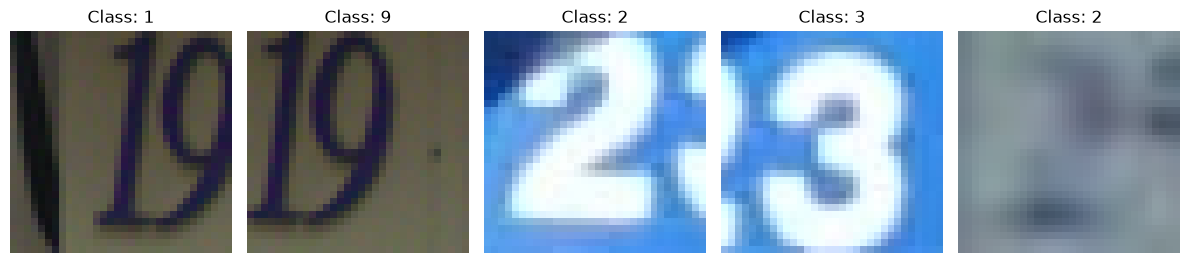

Sample images from the testing set:


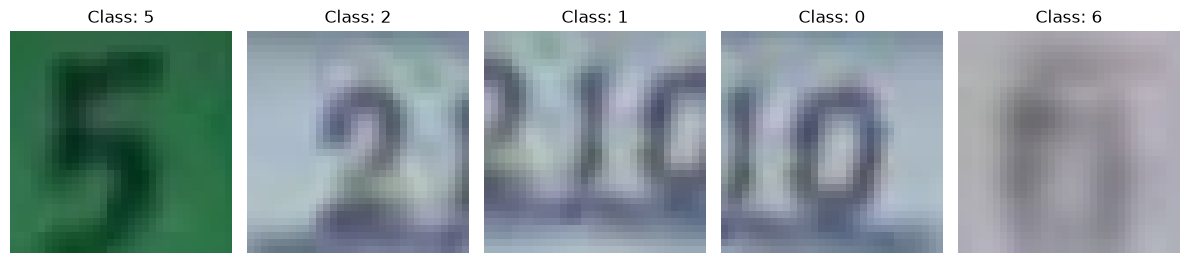

In [4]:
import scipy.io as sio

# Yuval Netzer, Tao Wang, Adam Coates, Alessandro Bissacco, Bo Wu, Andrew Y. Ng Reading Digits in Natural Images with Unsupervised Feature Learning NIPS Workshop on Deep Learning and Unsupervised Feature Learning 2011.

# # Load datasets
# train_data = sio.loadmat("train_32x32.mat")
# test_data = sio.loadmat("test_32x32.mat")

# # SVHN dataset stores images in format (32, 32, 3, N)
# # TensorFlow/Keras expects image data in format (N, 32, 32, 3)
# # 'np.transpose' to change dimensions

def stage_SVHN_data(train_path, test_path):
    """
    Load and preprocess the SVHN dataset.

    Parameters:
    train_path (str): Path to the training dataset (.mat file).
    test_path (str): Path to the testing dataset (.mat file).

    Returns:
    tuple: Preprocessed training and testing datasets.
    """
    # Load the data
    _train_data = sio.loadmat(train_path)
    _test_data = sio.loadmat(test_path)

    X_train = np.transpose(_train_data['X'], (3, 0, 1, 2))
    y_train = _train_data['y'].flatten()
    y_train[y_train == 10] = 0
    
    X_test = np.transpose(_test_data['X'], (3, 0, 1, 2))
    y_test = _test_data['y'].flatten()
    y_test[y_test == 10] = 0

    # Check if correct
    print("x_train shape:", X_train.shape)
    print("y_train shape:", y_train.shape)
    print("x_test shape:", X_test.shape)
    print("y_test shape:", y_test.shape)

    _class_names = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

    print("Sample images from the training set:")
    fig, axes = plt.subplots(1, 5, figsize=(12, 3))
    for i in range(5):
        axes[i].imshow(X_train[i])
        axes[i].set_title(f"Class: {_class_names[y_train[i]]}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

    print("Sample images from the testing set:")
    fig, axes = plt.subplots(1, 5, figsize=(12, 3))
    for i in range(5):
        axes[i].imshow(X_test[i])
        axes[i].set_title(f"Class: {_class_names[y_test[i]]}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

    # Normalize the data to the range [0, 1]
    X_train = X_train.astype("float32") / 255.0
    X_test = X_test.astype("float32") / 255.0

    return X_train, y_train, X_test, y_test

ex2_train_data, ex2_train_labels, ex2_test_data, ex2_test_labels = stage_SVHN_data("train_32x32.mat", "test_32x32.mat")

#### 2 b) Build a CNN model (10 points) 

Construct a Convolutional Neural Network (CNN) with at least 2 convolutional layers, 2 pooling layers, and 1 dense layer. You may optionally include normalization, dropout, or other regularization techniques to improve accuracy (in Part 2c). Explain and justify your modeling choices in your comments.

#### 2 c) Compile and train the network (10 points) 

Choose an optimizer (adjust the learning rate as needed) and a corresponding loss function.
Train the CNN for at least 20 epochs.
Use the test set as the validation set during training for simplicity.
Implement `Early Stopping`, monitoring the validation loss with a patience of 5.
Plot the training curves for both loss and accuracy.
Evaluate the trained model on the test set and report the test accuracy.

#### 2 d) Explaining the prediction on one test image (10 points)

Select a single test image (e.g., index i = 0) from the test dataset.
Print the model’s predicted probability distribution and the predicted class for that image.
Use LIME for image data to generate an explanation for the chosen test image through visualization.
Display the original image and the LIME explanation side by side.
Comment on the results and interpret the explanation.

### Exercise 3. Image denoising using Autoencoders (30 points)

In this exercise, you will use the CIFAR-10 dataset to investigate how effectively autoencoders can remove noise from images. You will first introduce artificial noise to the original images to create a noisy dataset. You will then build and train an autoencoder to reconstruct the original, noise-free images from their noisy counterparts. 
Finally, you will evaluate the denoising performance by comparing the reconstructed images with the original images.

#### 3 a) Load and prepare the data (5 points) 

Load the data from `keras.datasets.cifar10` and split it into input images (X) and class labels (y).
Print 10 images from the dataset and corresponding labels.
Normalize the pixel values to the range [0, 1].
Split the dataset into training and test sets (80% training, 20% test).
Print the shapes of `X_train`, `X_test`, `y_train`, and `y_test`

#### 3 b) Create and train an autoencoder (10 points) 

Generate noisy versions of the images by adding Gaussian noise to the original images. </span>
Build a fully connected FNN autoencoder for image denoising.
Choose an appropriate latent dimension and explain your choice.
Display a summary of your autoencoder model.
Compile the autoencoder using Mean Squared Error (MSE) as the loss function and the Adam optimizer.
Train the autoencoder on the noisy training images, using the test set as the validation set.

#### 3 c) Image denoising with CNN (15 points) 

Build a CNN for image denoising.
Use noisy images as inputs and their corresponding original, noise-free images as targets.
Use the same number of trainable layers as the autoencoder in 3b).
Use a convolutional output layer with 3 filters (RGB channels) and sigmoid activation so that the reconstructed pixel values are within the range [0, 1].
Compile the CNN using Mean Squared Error (MSE) as the loss function and the Adam optimizer.
Train the CNN on the noisy training images, using the test set as the validation set.
Compare denoising performance with that of the autoencoder.